# TA-EVRP RAPS Sweep Analysis

Analyses `results/ta_evrp_results_raps.csv` (PSL + SVC) and `results/ta_evrp_results_td.csv` (TD).

**RAPS sweep:** 3 planners × 90 zip rows (4 PSL K values × 3 nets × 6 agents  +  3 nets × 6 SVC agents) = 270 runs

**TD sweep:** TD-MILP planner × 15 zip rows (3 baselines × 3 nets + SARSA × 3 nets + DQN/A2C/PPO × 2 nets)

**Traffic models:**
- PSL (K=1–4): dijkstra, dsp, sarsa, dqn, a2c, ppo
- SVC: dijkstra, dsp, sarsa_svc, dqn_svc, a2c_svc, ppo_svc
- TD (3-period congestion): dijkstra, dsp, sarsa, dqn, a2c, ppo

In [1]:
from pathlib import Path
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})

CSV_PATH    = Path('../results/ta_evrp_results_raps.csv')
TD_CSV_PATH = Path('../results/ta_evrp_results_td.csv')

# ── Load RAPS (PSL + SVC) ─────────────────────────────────────────────────────
raw = pd.read_csv(CSV_PATH)
raw = raw[raw['status'] == 'ok'].copy()

# ── Derived columns ───────────────────────────────────────────────────────────
_NET_LABELS = {
    'grid_road':            'Grid',
    'rand_grid_road_final': 'RandGrid',
    'ames_campus_final':    'Ames',
}
raw['network']  = raw['network_net_path'].apply(lambda p: _NET_LABELS.get(Path(p).stem, Path(p).stem))
raw['planner']  = raw['evrp_planner'].map({'milp': 'MILP', 'heuristic': 'Heuristic', 'mtsp': 'mTSP'})
raw['agent']    = raw['trsp_agent']
raw['traffic']  = raw['traffic_model']                        # 'psl' | 'svc'
raw['K']        = pd.to_numeric(raw['traffic_psl_K'], errors='coerce')  # NaN for SVC rows
raw['throughput_tasks_per_h'] = raw['customers_served'] / raw['makespan_h'].replace(0, np.nan)

# ── Split by traffic model ────────────────────────────────────────────────────
psl_raw = raw[raw['traffic'] == 'psl'].copy()
svc_raw = raw[raw['traffic'] == 'svc'].copy()

# ── Load TD results ───────────────────────────────────────────────────────────
td_raw = pd.DataFrame()
if TD_CSV_PATH.exists():
    _td = pd.read_csv(TD_CSV_PATH)
    _td = _td[_td['status'] == 'ok'].copy()
    _td['network'] = _td['network_net_path'].apply(lambda p: _NET_LABELS.get(Path(p).stem, Path(p).stem))
    _td['planner'] = 'TD-MILP'
    _td['agent']   = _td['trsp_agent']
    _td['traffic'] = 'td'
    _td['throughput_tasks_per_h'] = _td['customers_served'] / _td['makespan_h'].replace(0, np.nan)
    td_raw = _td

# ── Style constants ───────────────────────────────────────────────────────────
PLANNER_ORDER  = [p for p in ['MILP', 'Heuristic', 'mTSP'] if p in raw['planner'].unique()]
NET_ORDER      = [n for n in ['Grid', 'RandGrid', 'Ames'] if n in raw['network'].unique()]
K_VALUES       = sorted(psl_raw['K'].dropna().astype(int).unique())

PSL_AGENT_ORDER = [a for a in ['dijkstra', 'dsp', 'sarsa', 'dqn', 'a2c', 'ppo']
                   if a in psl_raw['agent'].unique()]
SVC_AGENT_ORDER = [a for a in ['dijkstra', 'dsp', 'sarsa_svc', 'dqn_svc', 'a2c_svc', 'ppo_svc']
                   if a in svc_raw['agent'].unique()]
TD_AGENT_ORDER  = [a for a in ['dijkstra', 'dsp', 'sarsa', 'dqn', 'a2c', 'ppo']
                   if not td_raw.empty and a in td_raw['agent'].unique()]

PSL_AGENT_LABELS = {'dijkstra': 'Dijkstra', 'dsp': 'DSP',
                    'sarsa': 'SARSA', 'dqn': 'DQN', 'a2c': 'A2C', 'ppo': 'PPO'}
SVC_AGENT_LABELS = {'dijkstra': 'Dijkstra', 'dsp': 'DSP',
                    'sarsa_svc': 'SARSA-SVC', 'dqn_svc': 'DQN-SVC',
                    'a2c_svc': 'A2C-SVC', 'ppo_svc': 'PPO-SVC'}
TD_AGENT_LABELS  = PSL_AGENT_LABELS  # same agent names as PSL

PLANNER_COLORS = {'MILP': '#4C72B0', 'Heuristic': '#DD8452', 'mTSP': '#55A868'}
NET_LINESTYLES = {n: ls for n, ls in zip(NET_ORDER, ['-', '--', ':'])}
NET_MARKERS    = {n: m  for n, m  in zip(NET_ORDER, ['o', 's', '^'])}

_psl_palette = plt.cm.tab10(np.linspace(0, 0.9, max(len(PSL_AGENT_ORDER), 1)))
PSL_AGENT_COLORS = {a: _psl_palette[i] for i, a in enumerate(PSL_AGENT_ORDER)}
SVC_AGENT_COLORS = {
    'dijkstra':  '#888888',
    'dsp':       '#2ca02c',
    'sarsa_svc': '#9467bd',
    'dqn_svc':   '#4C72B0',
    'a2c_svc':   '#d62728',
    'ppo_svc':   '#17becf',
}
TD_AGENT_COLORS = PSL_AGENT_COLORS  # same color mapping as PSL agents

METRICS = ['makespan_s', 'total_distance_km', 'total_recharges',
           'customers_served', 'throughput_tasks_per_h', 'avg_inter_customer_gap_s']

# ── Deduplicated aggregate frames ─────────────────────────────────────────────
psl_df = psl_raw.groupby(['planner', 'agent', 'network', 'K'])[METRICS].mean().reset_index()
svc_df = svc_raw.groupby(['planner', 'agent', 'network'])[METRICS].mean().reset_index()
td_df  = (td_raw.groupby(['agent', 'network'])[METRICS].mean().reset_index()
          if not td_raw.empty else pd.DataFrame(columns=['agent', 'network'] + METRICS))

print(f"PSL rows: {len(psl_df)}  |  planners={PLANNER_ORDER}  |  agents={PSL_AGENT_ORDER}  |  K={K_VALUES}")
print(f"SVC rows: {len(svc_df)}  |  agents={SVC_AGENT_ORDER}  |  networks={NET_ORDER}")
print(f"TD  rows: {len(td_df)}   |  agents={TD_AGENT_ORDER}   |  networks={sorted(td_df['network'].unique().tolist()) if not td_df.empty else []}")

PSL rows: 216  |  planners=['MILP', 'Heuristic', 'mTSP']  |  agents=['dijkstra', 'dsp', 'sarsa', 'dqn', 'a2c', 'ppo']  |  K=[1, 2, 3, 4]
SVC rows: 54  |  agents=['dijkstra', 'dsp', 'sarsa_svc', 'dqn_svc', 'a2c_svc', 'ppo_svc']  |  networks=['Grid', 'RandGrid', 'Ames']
TD  rows: 15   |  agents=['dijkstra', 'dsp', 'sarsa', 'dqn', 'a2c', 'ppo']   |  networks=['Ames', 'Grid', 'RandGrid']


## Summary statistics

In [2]:
# PSL: mean over networks and K; SVC: mean over networks; TD: mean over networks
psl_summary = (
    psl_df.groupby(['planner', 'agent'])
    [['makespan_s', 'total_distance_km', 'total_recharges', 'customers_served', 'throughput_tasks_per_h']]
    .mean().round(2)
)
svc_summary = (
    svc_df.groupby(['planner', 'agent'])
    [['makespan_s', 'total_distance_km', 'total_recharges', 'customers_served', 'throughput_tasks_per_h']]
    .mean().round(2)
)
print("── PSL ──")
display(psl_summary)
print("── SVC ──")
display(svc_summary)

if not td_df.empty:
    td_summary = (
        td_df.groupby('agent')
        [['makespan_s', 'total_distance_km', 'total_recharges', 'customers_served', 'throughput_tasks_per_h']]
        .mean().round(2)
    )
    print("── TD ──")
    display(td_summary)

── PSL ──


makespan_s  total_distance_km  total_recharges  \
planner   agent                                                      
Heuristic a2c           472.33              13.11             0.00   
          dijkstra      444.50              12.89             0.00   
          dqn           426.00              13.69             0.00   
          dsp           449.17              12.72             0.00   
          ppo           422.75              13.23             0.00   
          sarsa         456.17              12.89             0.00   
MILP      a2c           729.50              10.83             1.67   
          dijkstra      716.92              10.56             1.67   
          dqn           677.00              10.62             1.67   
          dsp           716.92              10.56             1.67   
          ppo           728.58              10.74             1.67   
          sarsa         719.83              11.10             1.67   
mTSP      a2c           372.25              14.32             0.00   
          dijkstra      386.58              14.09             0.00   
          dqn           359.58              14.23             0.00   
          dsp           386.58              14.09             0.00   
          ppo           376.75              14.13             0.00   
          sarsa         383.42              15.11             0.00   

                    customers_served  throughput_tasks_per_h  
planner   agent                                               
Heuristic a2c                   10.0                  108.72  
          dijkstra              10.0                  113.87  
          dqn                   10.0                  115.10  
          dsp                   10.0                  113.59  
          ppo                   10.0                  115.78  
          sarsa                 10.0                  107.46  
MILP      a2c                   10.0                   74.21  
          dijkstra              10.0                   77.51  
          dqn                   10.0                   79.63  
          dsp                   10.0                   77.51  
          ppo                   10.0                   74.60  
          sarsa                 10.0                   68.60  
mTSP      a2c                   10.0                  134.32  
          dijkstra              10.0                  133.33  
          dqn                   10.0                  135.53  
          dsp                   10.0                  133.33  
          ppo                   10.0                  134.26  
          sarsa                 10.0                  122.48

── SVC ──


makespan_s  total_distance_km  total_recharges  \
planner   agent                                                       
Heuristic a2c_svc        607.67              12.39             0.33   
          dijkstra       558.00              12.39             0.00   
          dqn_svc        516.00              13.89             0.33   
          dsp            494.33              12.39             0.00   
          ppo_svc        554.33              12.39             0.00   
          sarsa_svc      587.67              12.34             0.00   
MILP      a2c_svc        732.00              11.24             1.67   
          dijkstra       717.33              10.56             1.67   
          dqn_svc        729.67              10.82             1.67   
          dsp            717.33              10.56             1.67   
          ppo_svc        720.00              10.58             1.67   
          sarsa_svc      770.00              11.26             1.67   
mTSP      a2c_svc        373.33              14.76             0.00   
          dijkstra       404.67              14.09             0.00   
          dqn_svc        390.00              14.56             0.00   
          dsp            404.67              14.09             0.00   
          ppo_svc        386.00              14.10             0.00   
          sarsa_svc      453.00              15.48             0.00   

                     customers_served  throughput_tasks_per_h  
planner   agent                                                
Heuristic a2c_svc                10.0                   81.72  
          dijkstra               10.0                   83.03  
          dqn_svc                10.0                   89.21  
          dsp                    10.0                   89.00  
          ppo_svc                10.0                   88.50  
          sarsa_svc              10.0                   82.95  
MILP      a2c_svc                10.0                   59.57  
          dijkstra               10.0                   60.89  
          dqn_svc                10.0                   58.37  
          dsp                    10.0                   60.89  
          ppo_svc                10.0                   60.13  
          sarsa_svc              10.0                   53.81  
mTSP      a2c_svc                10.0                  103.18  
          dijkstra               10.0                   99.98  
          dqn_svc                10.0                   99.28  
          dsp                    10.0                   99.98  
          ppo_svc                10.0                  100.73  
          sarsa_svc              10.0                   92.21

── TD ──


,makespan_s,total_distance_km,total_recharges,customers_served,throughput_tasks_per_h
agent,,,,,
a2c,973.50,8.87,0.50,7.50,52.73
dijkstra,1504.67,13.15,0.67,7.33,38.42
dqn,988.50,8.91,0.50,7.50,52.57
dsp,1504.67,13.15,0.67,7.33,38.42
ppo,981.00,8.94,0.50,7.50,50.53
sarsa,1503.00,13.28,0.67,7.33,38.53


---
## PSL Traffic

Piecewise Speed Limit model, K ∈ {1, 2, 3, 4}. K=2 uses slot_duration=300 s; K=1,3,4 use 60 s.

Agents: Dijkstra (static baseline), DSP (dynamic re-plan, non-learning), SARSA, DQN, A2C, PPO (RL).

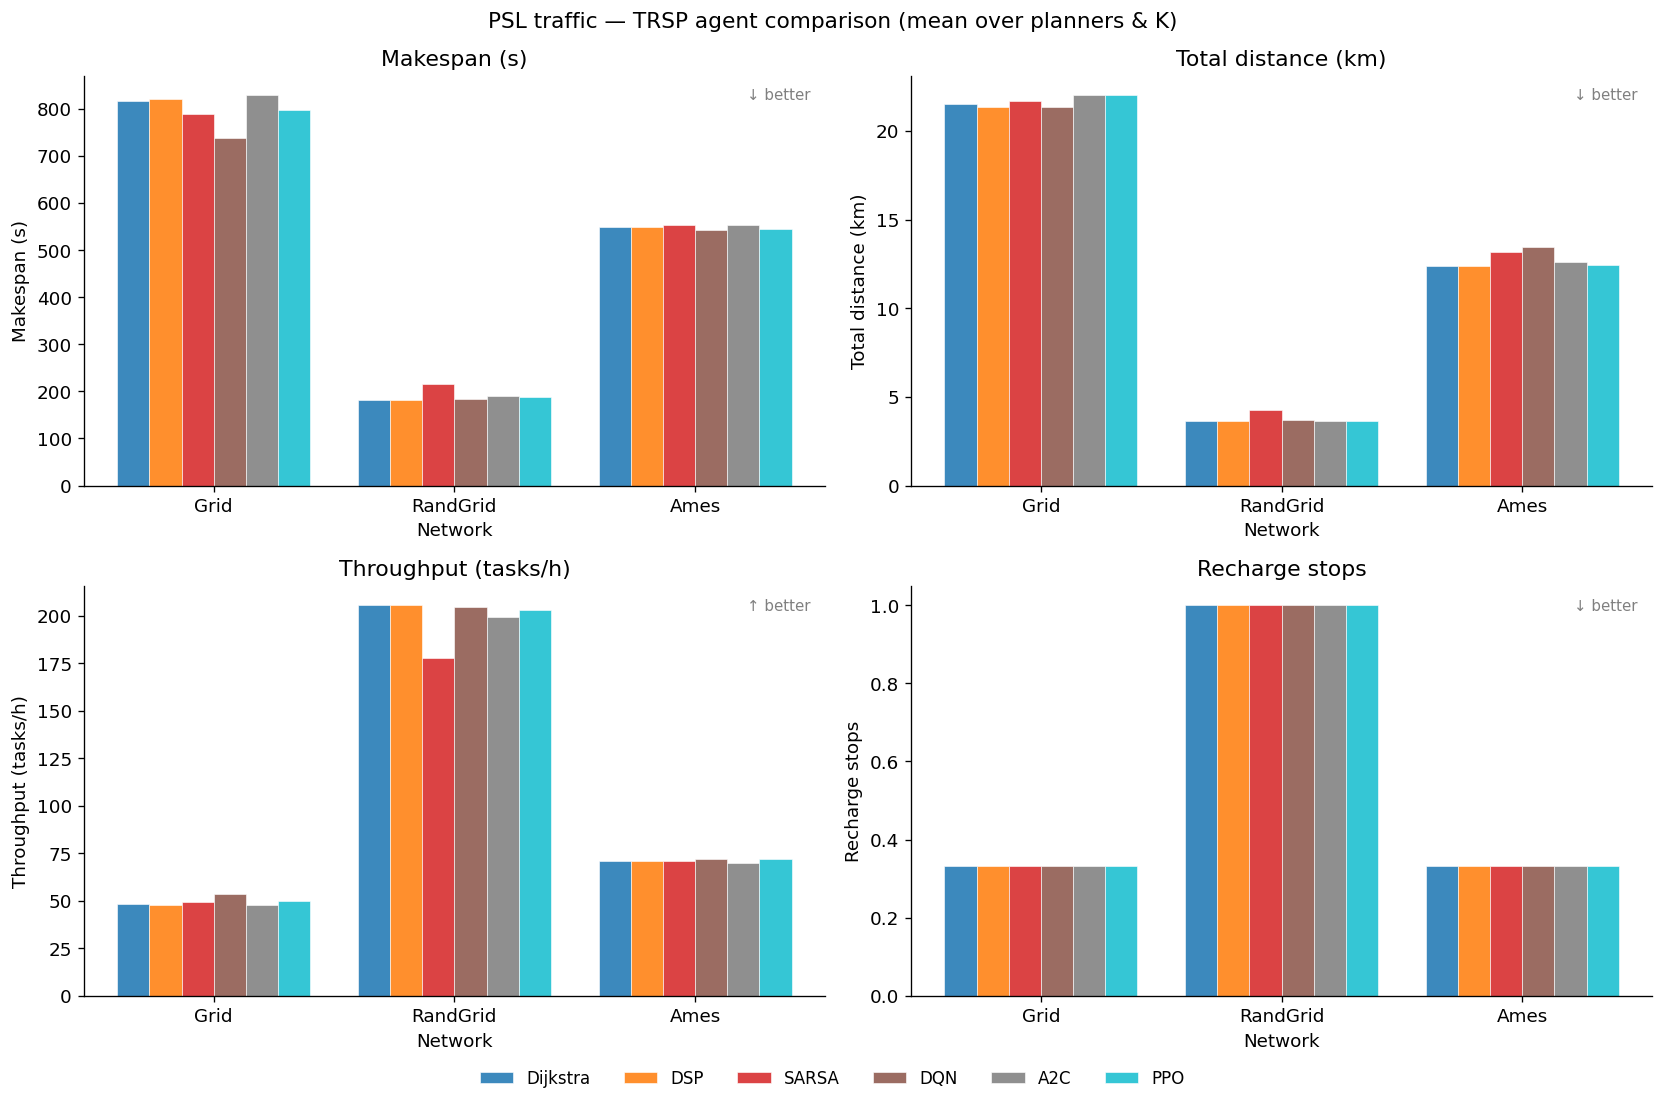

In [3]:
# ── PSL: agent comparison — bars per network, averaged over planners & K ──────
metrics_cfg = [
    ('makespan_s',             'Makespan (s)',         False),
    ('total_distance_km',      'Total distance (km)',  False),
    ('throughput_tasks_per_h', 'Throughput (tasks/h)', True),
    ('total_recharges',        'Recharge stops',       False),
]

agg = psl_df.groupby(['agent', 'network'])[METRICS].mean().reset_index()

x       = np.arange(len(NET_ORDER))
width   = 0.8 / len(PSL_AGENT_ORDER)
offsets = np.linspace(-(len(PSL_AGENT_ORDER)-1)/2*width,
                       (len(PSL_AGENT_ORDER)-1)/2*width, len(PSL_AGENT_ORDER))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('PSL traffic — TRSP agent comparison (mean over planners & K)', fontsize=13)

for ax, (metric, ylabel, higher_better) in zip(axes.flat, metrics_cfg):
    for offset, agent in zip(offsets, PSL_AGENT_ORDER):
        vals = [
            agg[(agg['agent'] == agent) & (agg['network'] == net)][metric].mean()
            for net in NET_ORDER
        ]
        ax.bar(x + offset, vals, width, color=PSL_AGENT_COLORS[agent], alpha=0.87,
               label=PSL_AGENT_LABELS.get(agent, agent), edgecolor='white', linewidth=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(NET_ORDER)
    ax.set_xlabel('Network')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.text(0.98, 0.97, '↑ better' if higher_better else '↓ better',
            transform=ax.transAxes, ha='right', va='top', fontsize=9, color='gray')

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(PSL_AGENT_ORDER),
           bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

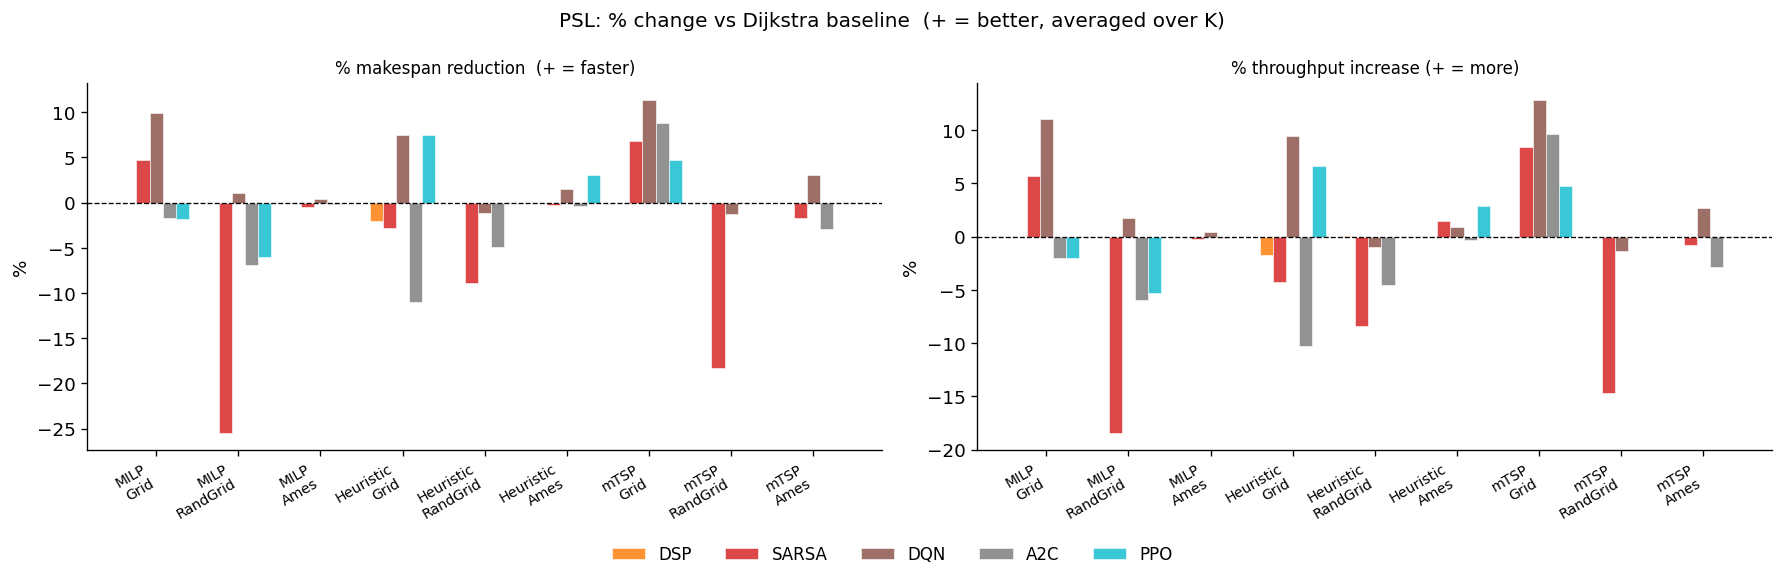

In [4]:
# ── PSL: RL + DSP improvement over Dijkstra — per planner × network ───────────
# Positive = better than Dijkstra (faster / higher throughput)
PSL_RL = [a for a in PSL_AGENT_ORDER if a != 'dijkstra']

pn = psl_df.groupby(['planner', 'agent', 'network'])[METRICS].mean().reset_index()

combo_labels, delta = [], {a: {'ms': [], 'tp': []} for a in PSL_RL}
for pl in PLANNER_ORDER:
    for net in NET_ORDER:
        base = pn[(pn['planner'] == pl) & (pn['agent'] == 'dijkstra') & (pn['network'] == net)]
        if base.empty:
            continue
        b_ms = base['makespan_s'].values[0]
        b_tp = base['throughput_tasks_per_h'].values[0]
        combo_labels.append(f'{pl}\n{net}')
        for a in PSL_RL:
            rl = pn[(pn['planner'] == pl) & (pn['agent'] == a) & (pn['network'] == net)]
            if rl.empty:
                delta[a]['ms'].append(np.nan)
                delta[a]['tp'].append(np.nan)
            else:
                r_ms = rl['makespan_s'].values[0]
                r_tp = rl['throughput_tasks_per_h'].values[0]
                delta[a]['ms'].append(-(r_ms - b_ms) / max(abs(b_ms), 1e-9) * 100)
                delta[a]['tp'].append((r_tp - b_tp) / max(abs(b_tp), 1e-9) * 100)

x2      = np.arange(len(combo_labels))
width2  = 0.8 / max(len(PSL_RL), 1)
off2    = np.linspace(-(len(PSL_RL)-1)/2*width2, (len(PSL_RL)-1)/2*width2, len(PSL_RL))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
fig.suptitle('PSL: % change vs Dijkstra baseline  (+ = better, averaged over K)', fontsize=12)

for ax, (col, title) in zip(axes, [
    ('ms', '% makespan reduction  (+ = faster)'),
    ('tp', '% throughput increase (+ = more)'),
]):
    for off, a in zip(off2, PSL_RL):
        ax.bar(x2 + off, delta[a][col], width2, color=PSL_AGENT_COLORS[a], alpha=0.85,
               label=PSL_AGENT_LABELS.get(a, a), edgecolor='white', linewidth=0.4)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_xticks(x2)
    ax.set_xticklabels(combo_labels, fontsize=8.5, rotation=30, ha='right')
    ax.set_ylabel('%')
    ax.set_title(title, fontsize=10)

handles, lbls = axes[0].get_legend_handles_labels()
fig.legend(handles, lbls, loc='lower center', ncol=len(PSL_RL),
           bbox_to_anchor=(0.5, -0.07), frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

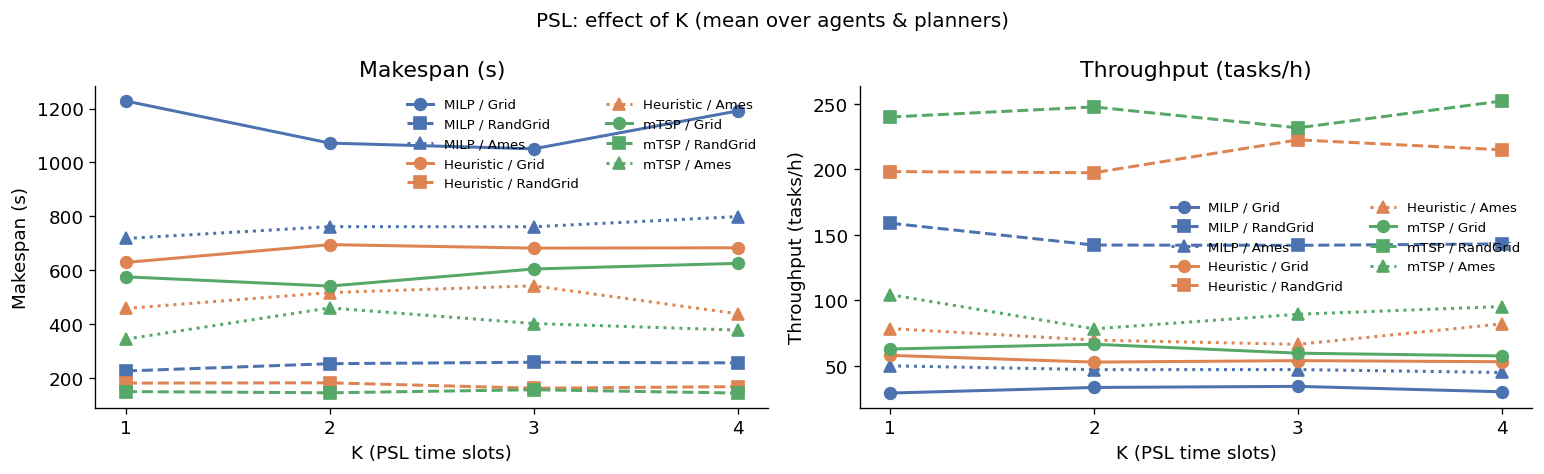

In [5]:
# ── PSL: effect of K (averaged over agents and planners) ──────────────────────
if len(K_VALUES) < 2:
    print("Only one K value present.")
else:
    agg_k = psl_df.groupby(['planner', 'network', 'K'])[METRICS].mean().reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle('PSL: effect of K (mean over agents & planners)', fontsize=12)

    for ax, (metric, ylabel) in zip(axes, [
        ('makespan_s',             'Makespan (s)'),
        ('throughput_tasks_per_h', 'Throughput (tasks/h)'),
    ]):
        for planner in PLANNER_ORDER:
            for net in NET_ORDER:
                sub = agg_k[(agg_k['planner'] == planner) & (agg_k['network'] == net)].sort_values('K')
                if sub.empty:
                    continue
                ax.plot(
                    sub['K'], sub[metric],
                    color=PLANNER_COLORS.get(planner, '#888'),
                    linestyle=NET_LINESTYLES.get(net, '-'),
                    marker=NET_MARKERS.get(net, 'o'),
                    label=f'{planner} / {net}',
                    markersize=7, linewidth=1.8,
                )
        ax.set_xlabel('K (PSL time slots)')
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel)
        ax.set_xticks(K_VALUES)
        ax.legend(frameon=False, fontsize=8, ncol=2)

    fig.tight_layout()
    plt.show()

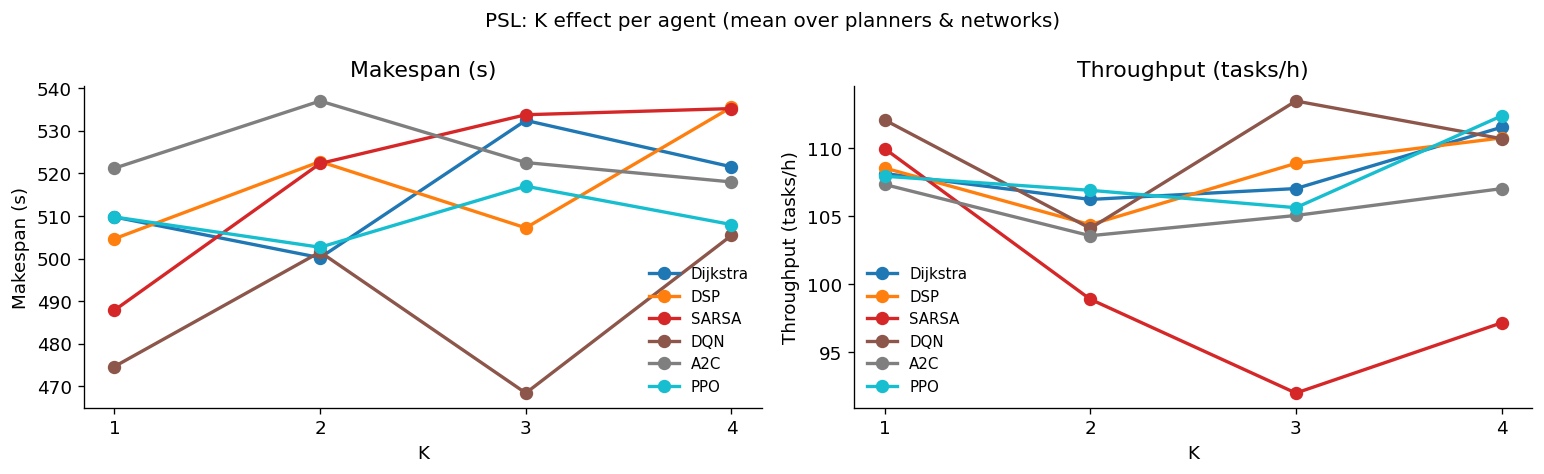

In [6]:
# ── PSL: K effect per agent (averaged over planners & networks) ───────────────
if len(K_VALUES) >= 2:
    agg_ka = psl_df.groupby(['agent', 'K'])[['makespan_s', 'throughput_tasks_per_h']].mean().reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle('PSL: K effect per agent (mean over planners & networks)', fontsize=12)

    for ax, (metric, ylabel) in zip(axes, [
        ('makespan_s',             'Makespan (s)'),
        ('throughput_tasks_per_h', 'Throughput (tasks/h)'),
    ]):
        for agent in PSL_AGENT_ORDER:
            sub = agg_ka[agg_ka['agent'] == agent].sort_values('K')
            ax.plot(sub['K'], sub[metric],
                    color=PSL_AGENT_COLORS[agent], marker='o', linewidth=2, markersize=7,
                    label=PSL_AGENT_LABELS.get(agent, agent))
        ax.set_xlabel('K')
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel)
        ax.set_xticks(K_VALUES)
        ax.legend(frameon=False, fontsize=9)

    fig.tight_layout()
    plt.show()

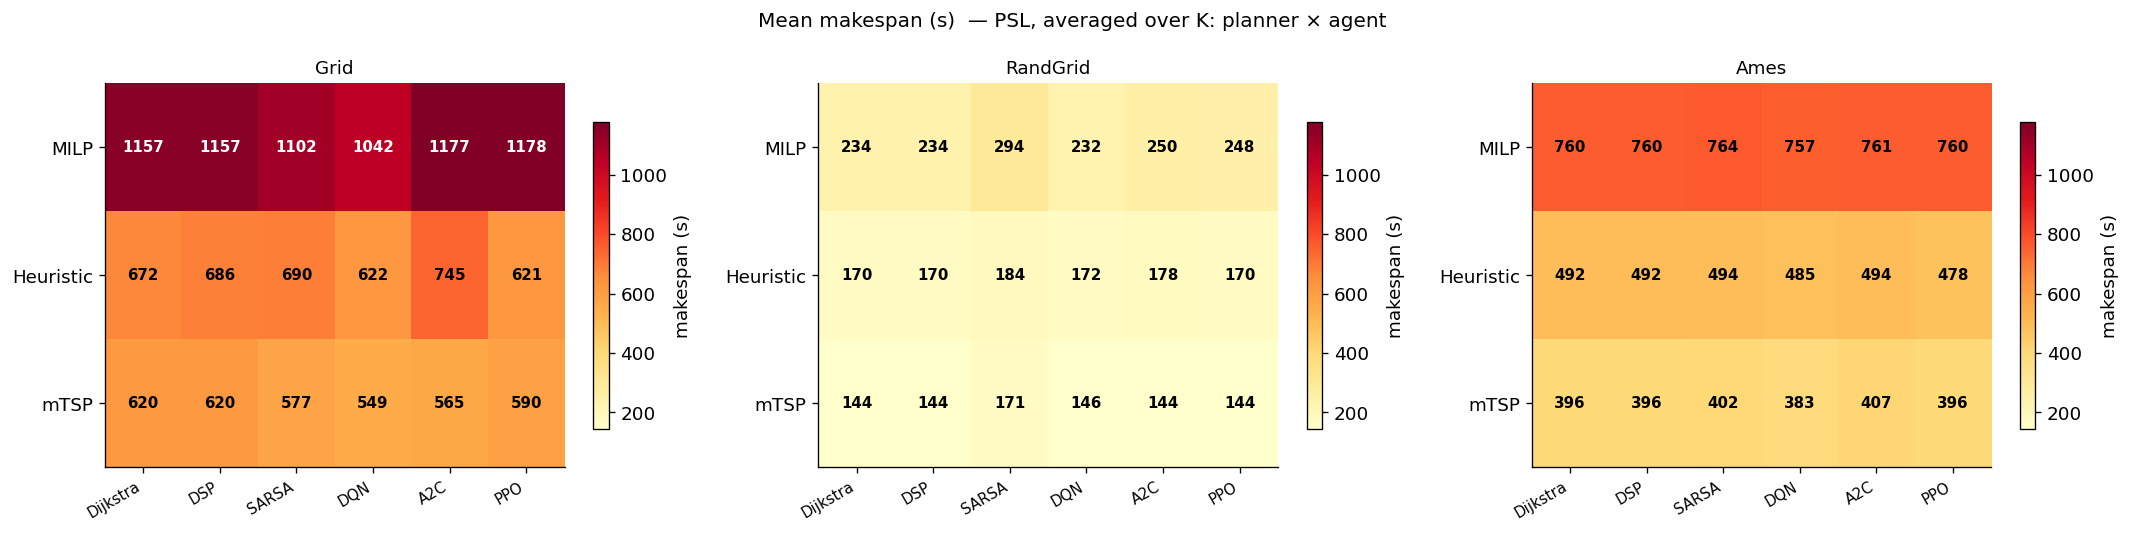

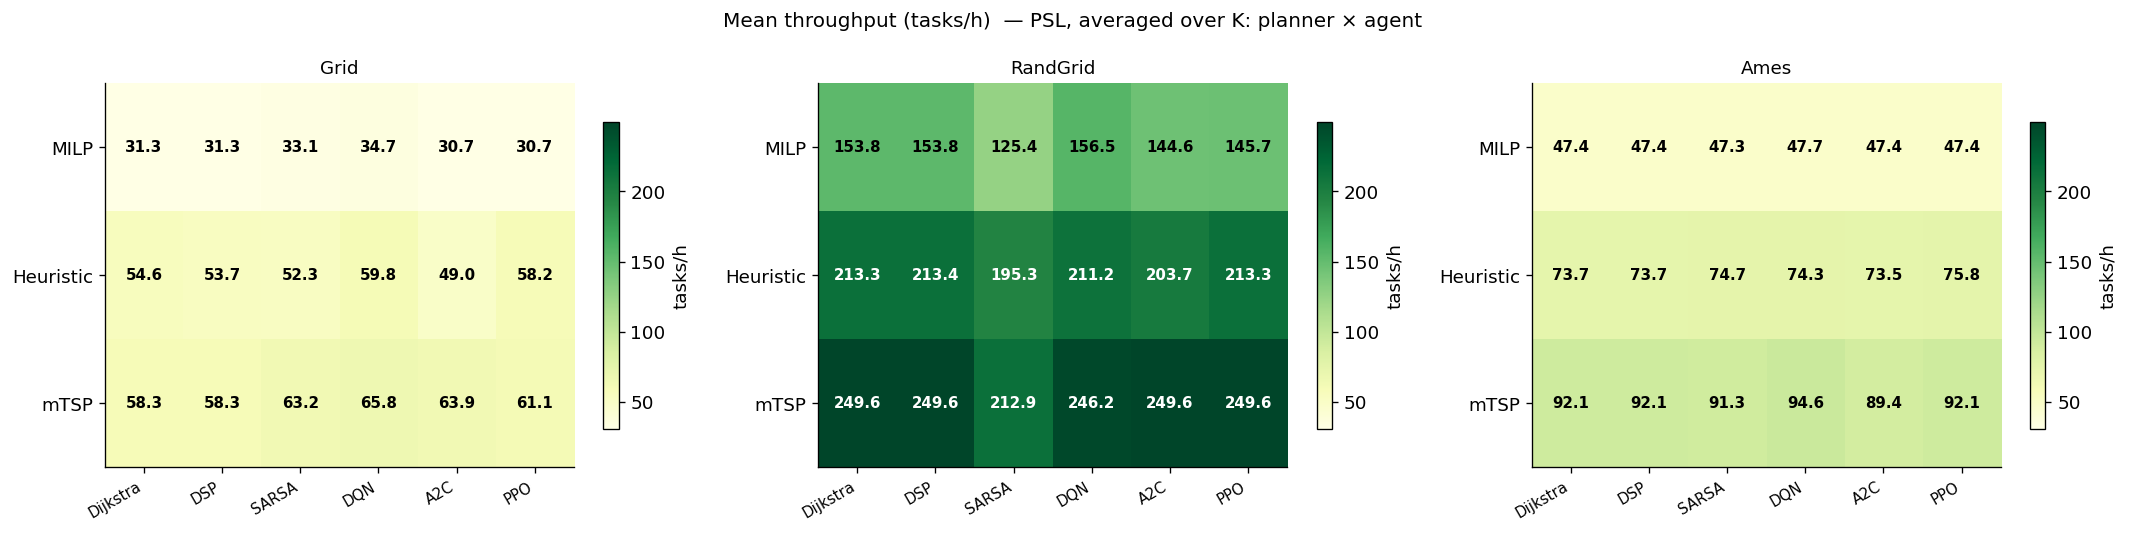

In [7]:
# ── PSL: heatmaps — makespan and throughput, planner × agent (per network) ────
for metric, cmap, label, title in [
    ('makespan_s',             'YlOrRd', 'makespan (s)',  'Mean makespan (s)  — PSL, averaged over K'),
    ('throughput_tasks_per_h', 'YlGn',   'tasks/h',       'Mean throughput (tasks/h)  — PSL, averaged over K'),
]:
    fig, axes = plt.subplots(1, len(NET_ORDER), figsize=(6 * len(NET_ORDER), 4.5), squeeze=False)
    fig.suptitle(f'{title}: planner × agent', fontsize=12)

    agg_heat = psl_df.groupby(['planner', 'agent', 'network'])[metric].mean()
    valid = agg_heat[agg_heat > 0].values
    vmin, vmax = (valid.min(), valid.max()) if len(valid) else (0, 1)

    for ax, net in zip(axes[0], NET_ORDER):
        sub = (psl_df[psl_df['network'] == net]
               .groupby(['planner', 'agent'])[metric].mean()
               .unstack('agent')
               .reindex(index=PLANNER_ORDER, columns=PSL_AGENT_ORDER))
        vals = sub.values.astype(float)
        im = ax.imshow(vals, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_xticks(range(len(PSL_AGENT_ORDER)))
        ax.set_xticklabels([PSL_AGENT_LABELS.get(a, a) for a in PSL_AGENT_ORDER], rotation=30, ha='right', fontsize=9)
        ax.set_yticks(range(len(PLANNER_ORDER)))
        ax.set_yticklabels(PLANNER_ORDER)
        ax.set_title(net, fontsize=11)
        for i in range(len(PLANNER_ORDER)):
            for j in range(len(PSL_AGENT_ORDER)):
                v = vals[i, j]
                if not np.isnan(v):
                    brightness = (v - vmin) / (vmax - vmin + 1e-9)
                    fmt = f'{v:.0f}' if metric == 'makespan_s' else f'{v:.1f}'
                    ax.text(j, i, fmt, ha='center', va='center', fontsize=9,
                            color='white' if brightness > 0.6 else 'black', fontweight='bold')
        plt.colorbar(im, ax=ax, shrink=0.8, label=label)

    fig.tight_layout()
    plt.show()

---
## SVC Traffic

Stochastic Vehicular Congestion — live background SUMO vehicles. Traffic scales: Grid=1.5, RandGrid=2.5, Ames=2.0.

Agents: Dijkstra (static baseline), DSP (dynamic re-plan, non-learning), SARSA-SVC, DQN-SVC, A2C-SVC, PPO-SVC (RL trained on SVC).

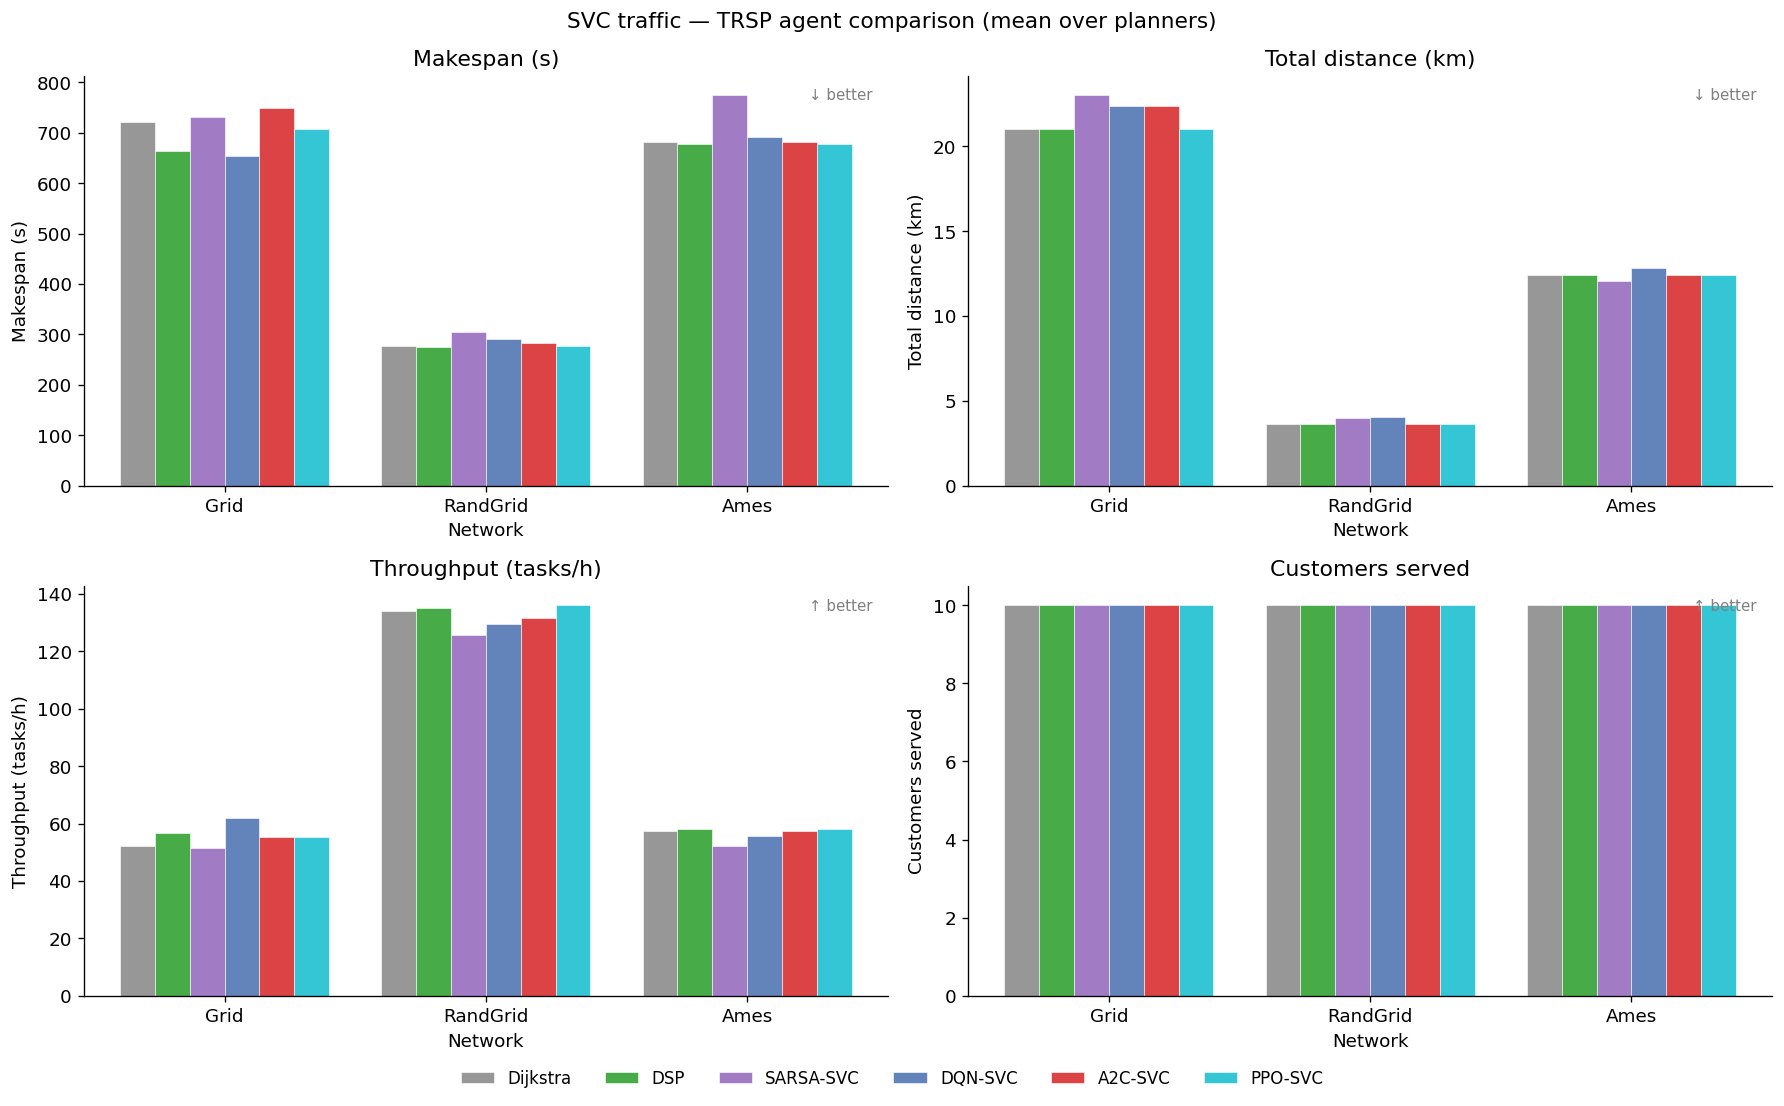

In [8]:
# ── SVC: agent comparison — bars per network, averaged over planners ──────────
svc_agg = svc_df.groupby(['agent', 'network'])[METRICS].mean().reset_index()

x       = np.arange(len(NET_ORDER))
width   = 0.8 / len(SVC_AGENT_ORDER)
offsets = np.linspace(-(len(SVC_AGENT_ORDER)-1)/2*width,
                       (len(SVC_AGENT_ORDER)-1)/2*width, len(SVC_AGENT_ORDER))

svc_metrics_cfg = [
    ('makespan_s',             'Makespan (s)',         False),
    ('total_distance_km',      'Total distance (km)',  False),
    ('throughput_tasks_per_h', 'Throughput (tasks/h)', True),
    ('customers_served',       'Customers served',     True),
]

fig, axes = plt.subplots(2, 2, figsize=(max(14, 2.5 * len(SVC_AGENT_ORDER)), 9))
fig.suptitle('SVC traffic — TRSP agent comparison (mean over planners)', fontsize=13)

for ax, (metric, ylabel, higher_better) in zip(axes.flat, svc_metrics_cfg):
    for offset, agent in zip(offsets, SVC_AGENT_ORDER):
        vals = [
            svc_agg[(svc_agg['agent'] == agent) & (svc_agg['network'] == net)][metric].mean()
            for net in NET_ORDER
        ]
        ax.bar(x + offset, vals, width, color=SVC_AGENT_COLORS.get(agent, '#888'), alpha=0.87,
               label=SVC_AGENT_LABELS.get(agent, agent), edgecolor='white', linewidth=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(NET_ORDER)
    ax.set_xlabel('Network')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.text(0.98, 0.97, '↑ better' if higher_better else '↓ better',
            transform=ax.transAxes, ha='right', va='top', fontsize=9, color='gray')

handles, labels = axes.flat[0].get_legend_handles_labels()
seen, uh, ul = set(), [], []
for h, l in zip(handles, labels):
    if l not in seen:
        seen.add(l); uh.append(h); ul.append(l)
fig.legend(uh, ul, loc='lower center', ncol=len(SVC_AGENT_ORDER),
           bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

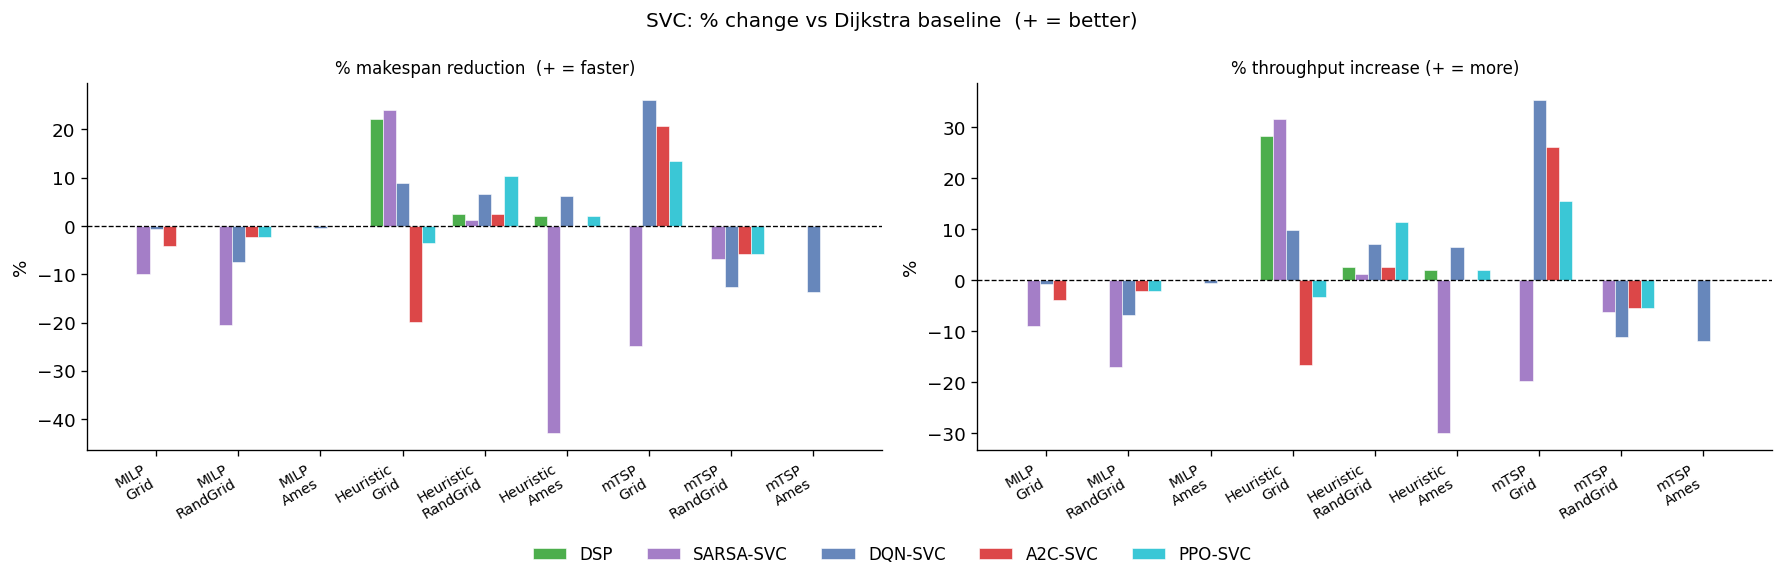

In [9]:
# ── SVC: % improvement over Dijkstra — per planner × network ─────────────────
SVC_RL = [a for a in SVC_AGENT_ORDER if a != 'dijkstra']

pn_svc = svc_df.groupby(['planner', 'agent', 'network'])[METRICS].mean().reset_index()

svc_labels, svc_delta = [], {a: {'ms': [], 'tp': []} for a in SVC_RL}
for pl in PLANNER_ORDER:
    for net in NET_ORDER:
        base = pn_svc[(pn_svc['planner'] == pl) & (pn_svc['agent'] == 'dijkstra') & (pn_svc['network'] == net)]
        if base.empty:
            continue
        b_ms = base['makespan_s'].values[0]
        b_tp = base['throughput_tasks_per_h'].values[0]
        svc_labels.append(f'{pl}\n{net}')
        for a in SVC_RL:
            rl = pn_svc[(pn_svc['planner'] == pl) & (pn_svc['agent'] == a) & (pn_svc['network'] == net)]
            if rl.empty:
                svc_delta[a]['ms'].append(np.nan)
                svc_delta[a]['tp'].append(np.nan)
            else:
                r_ms = rl['makespan_s'].values[0]
                r_tp = rl['throughput_tasks_per_h'].values[0]
                svc_delta[a]['ms'].append(-(r_ms - b_ms) / max(abs(b_ms), 1e-9) * 100)
                svc_delta[a]['tp'].append((r_tp - b_tp) / max(abs(b_tp), 1e-9) * 100)

x3      = np.arange(len(svc_labels))
width3  = 0.8 / max(len(SVC_RL), 1)
off3    = np.linspace(-(len(SVC_RL)-1)/2*width3, (len(SVC_RL)-1)/2*width3, len(SVC_RL))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
fig.suptitle('SVC: % change vs Dijkstra baseline  (+ = better)', fontsize=12)

for ax, (col, title) in zip(axes, [
    ('ms', '% makespan reduction  (+ = faster)'),
    ('tp', '% throughput increase (+ = more)'),
]):
    for off, a in zip(off3, SVC_RL):
        ax.bar(x3 + off, svc_delta[a][col], width3,
               color=SVC_AGENT_COLORS.get(a, '#888'), alpha=0.85,
               label=SVC_AGENT_LABELS.get(a, a), edgecolor='white', linewidth=0.4)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_xticks(x3)
    ax.set_xticklabels(svc_labels, fontsize=8.5, rotation=30, ha='right')
    ax.set_ylabel('%')
    ax.set_title(title, fontsize=10)

handles, lbls = axes[0].get_legend_handles_labels()
fig.legend(handles, lbls, loc='lower center', ncol=len(SVC_RL),
           bbox_to_anchor=(0.5, -0.07), frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

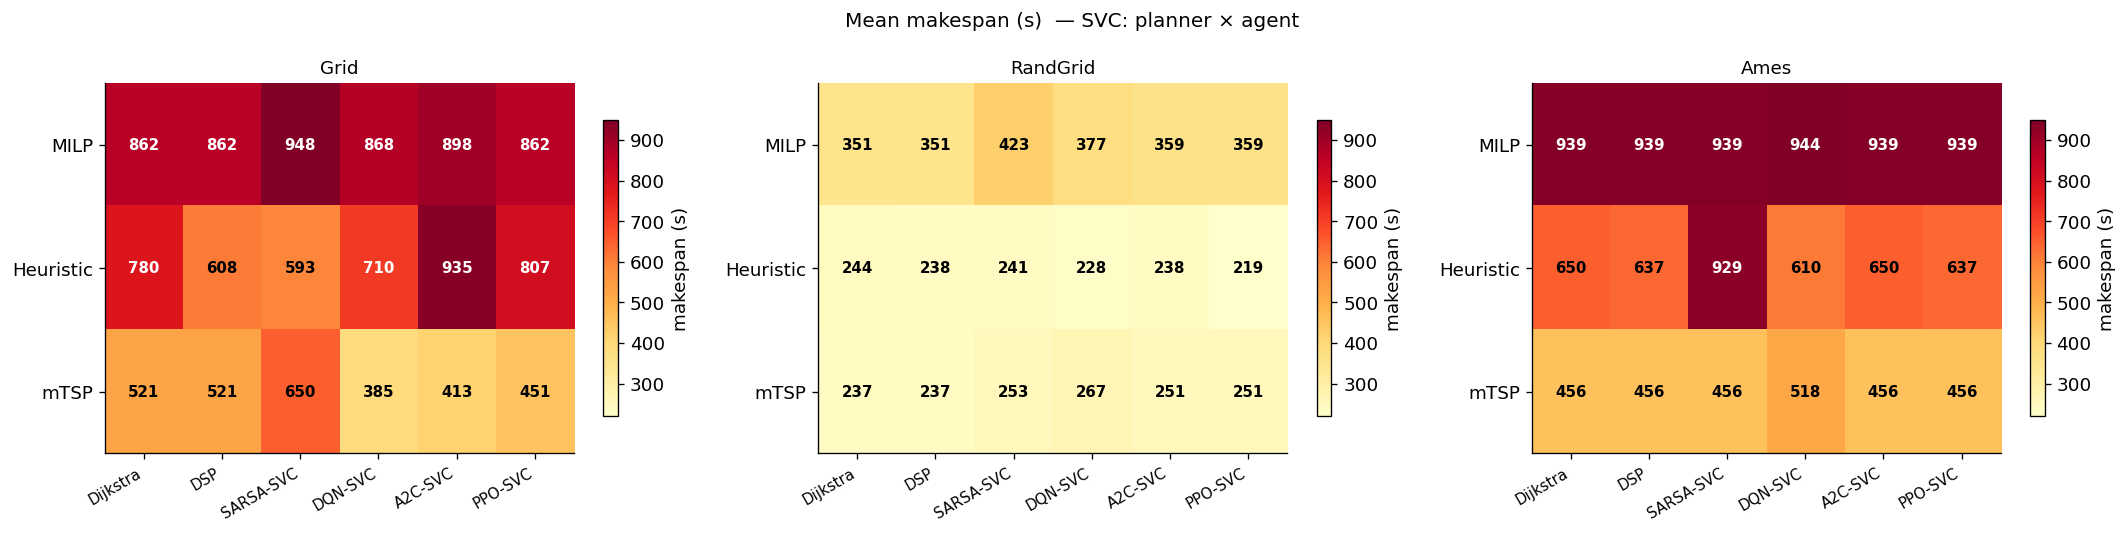

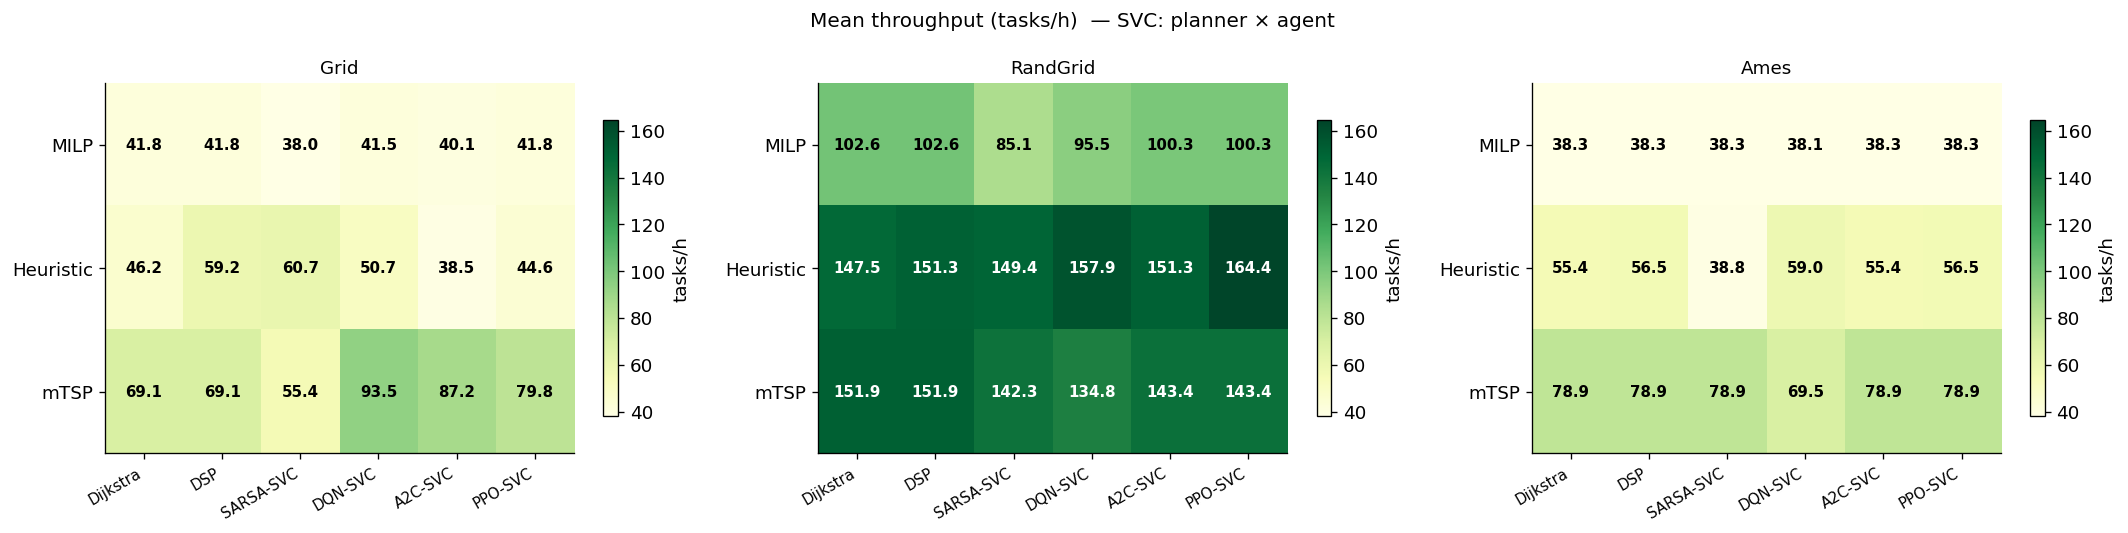

In [10]:
# ── SVC: heatmaps — makespan and throughput, planner × agent (per network) ────
for metric, cmap, label, title in [
    ('makespan_s',             'YlOrRd', 'makespan (s)', 'Mean makespan (s)  — SVC'),
    ('throughput_tasks_per_h', 'YlGn',   'tasks/h',      'Mean throughput (tasks/h)  — SVC'),
]:
    fig, axes = plt.subplots(1, len(NET_ORDER), figsize=(6 * len(NET_ORDER), 4.5), squeeze=False)
    fig.suptitle(f'{title}: planner × agent', fontsize=12)

    valid = svc_df[svc_df[metric] > 0][metric].values
    vmin, vmax = (valid.min(), valid.max()) if len(valid) else (0, 1)

    for ax, net in zip(axes[0], NET_ORDER):
        sub = (svc_df[svc_df['network'] == net]
               .groupby(['planner', 'agent'])[metric].mean()
               .unstack('agent')
               .reindex(index=PLANNER_ORDER, columns=SVC_AGENT_ORDER))
        vals = sub.values.astype(float)
        im = ax.imshow(vals, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_xticks(range(len(SVC_AGENT_ORDER)))
        ax.set_xticklabels([SVC_AGENT_LABELS.get(a, a) for a in SVC_AGENT_ORDER],
                           rotation=30, ha='right', fontsize=9)
        ax.set_yticks(range(len(PLANNER_ORDER)))
        ax.set_yticklabels(PLANNER_ORDER)
        ax.set_title(net, fontsize=11)
        for i in range(len(PLANNER_ORDER)):
            for j in range(len(SVC_AGENT_ORDER)):
                v = vals[i, j]
                if not np.isnan(v):
                    brightness = (v - vmin) / (vmax - vmin + 1e-9)
                    fmt = f'{v:.0f}' if metric == 'makespan_s' else f'{v:.1f}'
                    ax.text(j, i, fmt, ha='center', va='center', fontsize=9,
                            color='white' if brightness > 0.6 else 'black', fontweight='bold')
        plt.colorbar(im, ax=ax, shrink=0.8, label=label)

    fig.tight_layout()
    plt.show()

---
## TD Traffic

Three-period time-of-day congestion (Lu et al. 2020): congestion speed v_c=10 km/h in slots 0 & 2 (peak), free-flow v_f=40 km/h in slot 1 (midday). Planner: TD-MILP (departure-time-aware exact solver).

Agents: Dijkstra (static baseline), DSP (dynamic re-plan), SARSA, DQN, A2C, PPO (RL trained on TD traffic).
Note: DQN, A2C, PPO were only trained on RandGrid and Ames; no TD-trained policy exists for Grid.

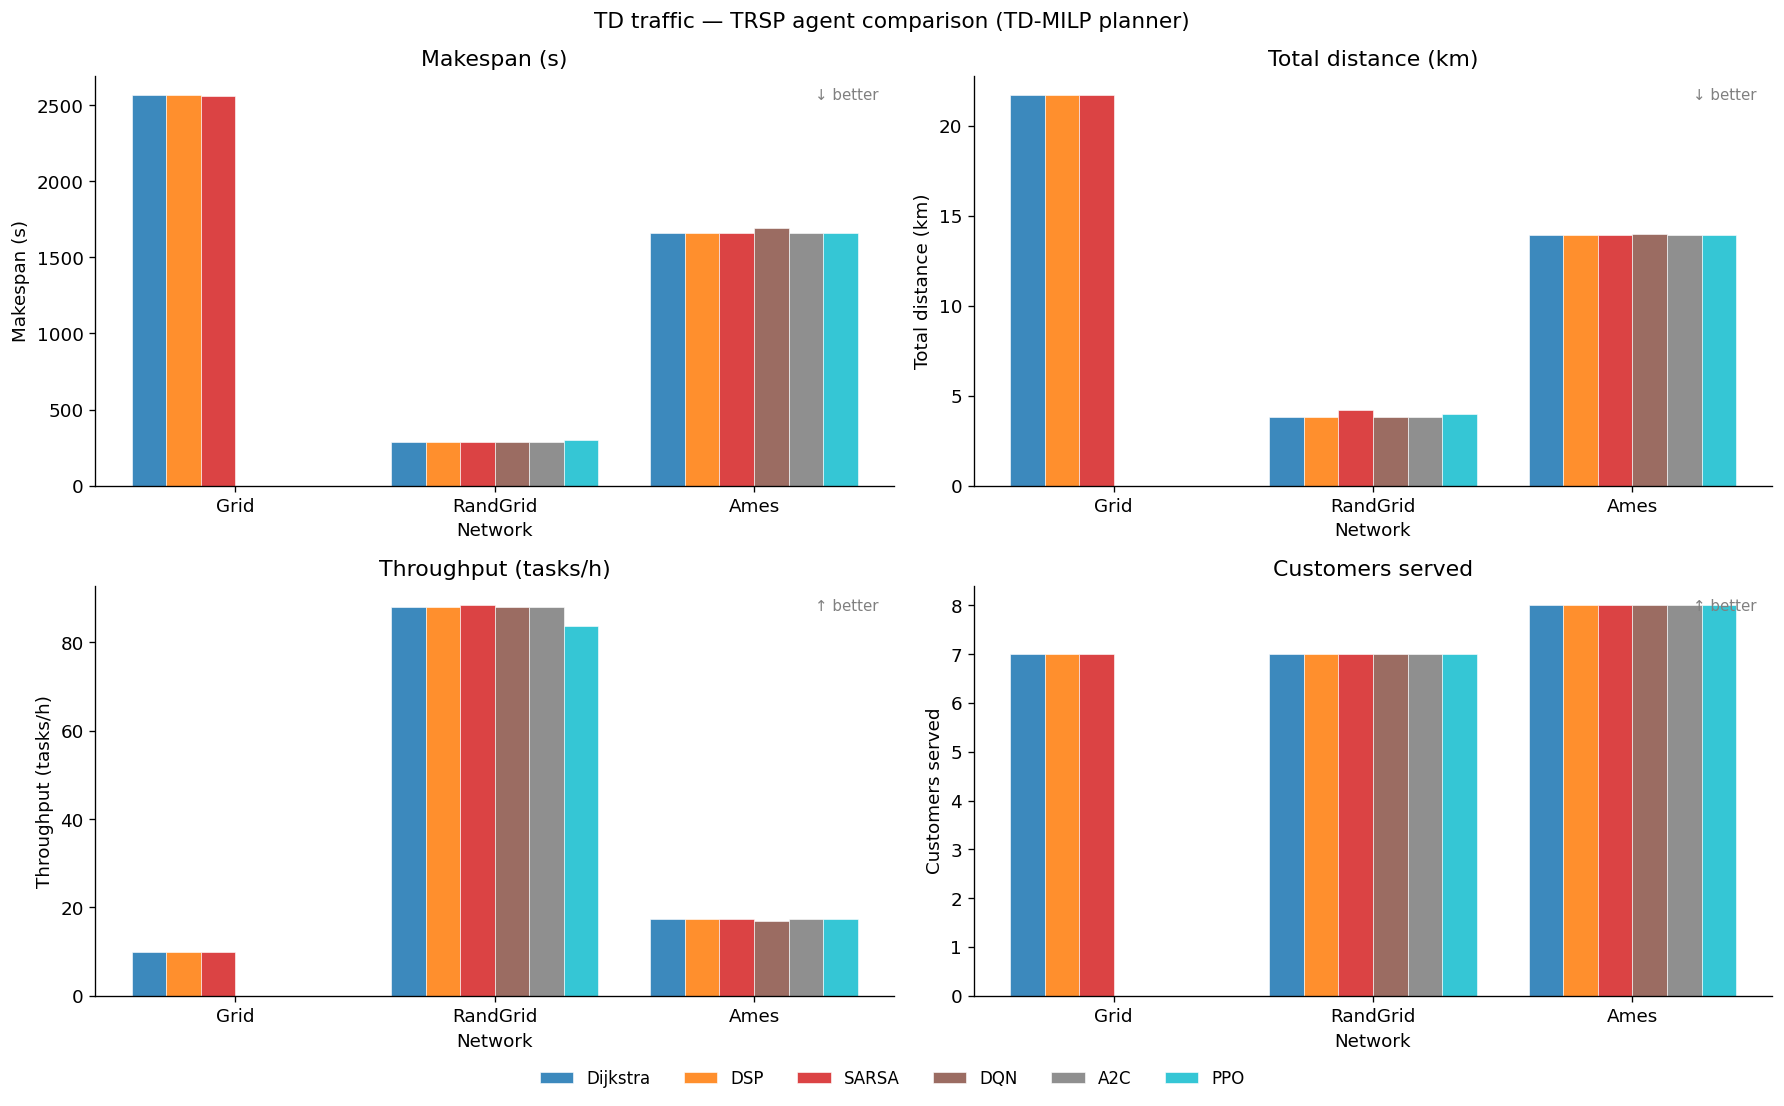

In [11]:
# ── TD: agent comparison — bars per network ───────────────────────────────────
if td_df.empty or not TD_AGENT_ORDER:
    print("No TD results loaded — run the TD sweep first.")
else:
    td_nets = [n for n in NET_ORDER if n in td_df['network'].unique()]
    x       = np.arange(len(td_nets))
    width   = 0.8 / len(TD_AGENT_ORDER)
    offsets = np.linspace(-(len(TD_AGENT_ORDER)-1)/2*width,
                           (len(TD_AGENT_ORDER)-1)/2*width, len(TD_AGENT_ORDER))

    td_metrics_cfg = [
        ('makespan_s',             'Makespan (s)',         False),
        ('total_distance_km',      'Total distance (km)',  False),
        ('throughput_tasks_per_h', 'Throughput (tasks/h)', True),
        ('customers_served',       'Customers served',     True),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(max(12, 2.5 * len(TD_AGENT_ORDER)), 9))
    fig.suptitle('TD traffic — TRSP agent comparison (TD-MILP planner)', fontsize=13)

    for ax, (metric, ylabel, higher_better) in zip(axes.flat, td_metrics_cfg):
        for offset, agent in zip(offsets, TD_AGENT_ORDER):
            vals = [
                td_df[(td_df['agent'] == agent) & (td_df['network'] == net)][metric].mean()
                for net in td_nets
            ]
            ax.bar(x + offset, vals, width,
                   color=TD_AGENT_COLORS.get(agent, '#aaaaaa'), alpha=0.87,
                   label=TD_AGENT_LABELS.get(agent, agent), edgecolor='white', linewidth=0.4)
        ax.set_xticks(x)
        ax.set_xticklabels(td_nets)
        ax.set_xlabel('Network')
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel)
        ax.text(0.98, 0.97, '↑ better' if higher_better else '↓ better',
                transform=ax.transAxes, ha='right', va='top', fontsize=9, color='gray')

    handles, labels = axes.flat[0].get_legend_handles_labels()
    seen, uh, ul = set(), [], []
    for h, l in zip(handles, labels):
        if l not in seen:
            seen.add(l); uh.append(h); ul.append(l)
    fig.legend(uh, ul, loc='lower center', ncol=len(TD_AGENT_ORDER),
               bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=10)
    fig.tight_layout()
    plt.show()

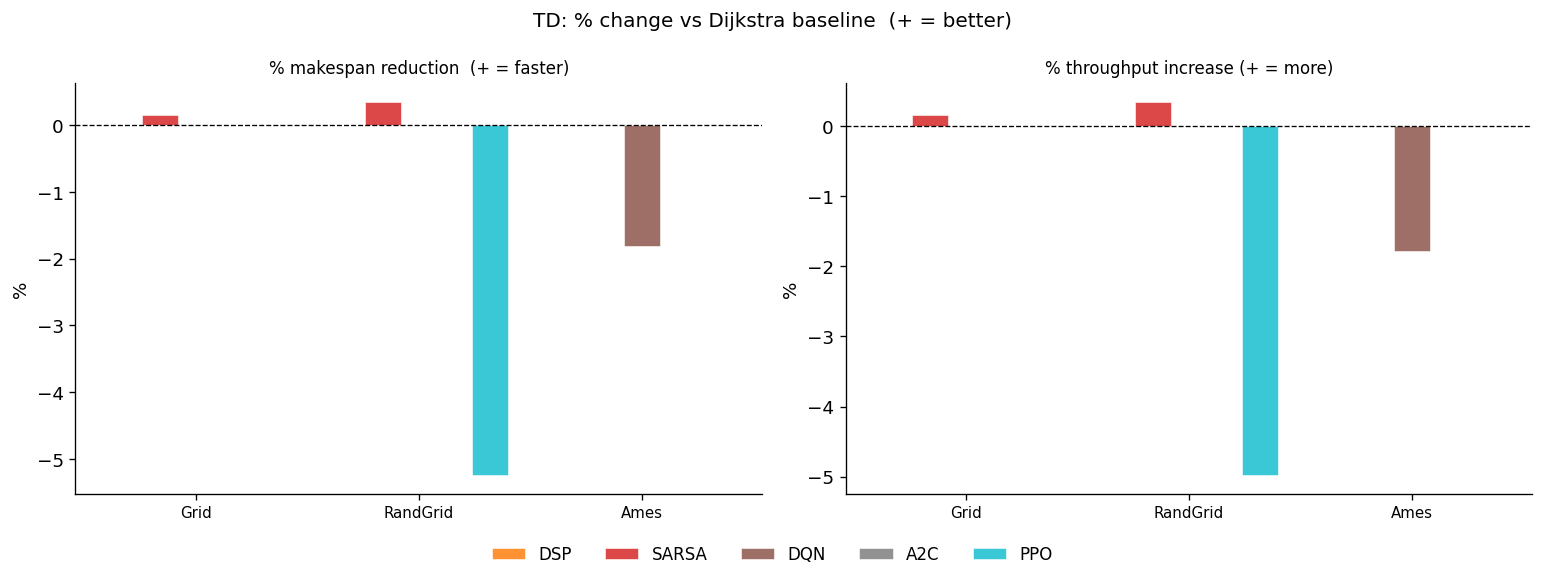

In [12]:
# ── TD: % improvement over Dijkstra — per network ─────────────────────────────
if not td_df.empty and len(TD_AGENT_ORDER) > 1:
    TD_RL = [a for a in TD_AGENT_ORDER if a != 'dijkstra']
    td_nets = [n for n in NET_ORDER if n in td_df['network'].unique()]

    td_labels = []
    td_delta  = {a: {'ms': [], 'tp': []} for a in TD_RL}

    for net in td_nets:
        base = td_df[(td_df['agent'] == 'dijkstra') & (td_df['network'] == net)]
        if base.empty:
            continue
        b_ms = base['makespan_s'].values[0]
        b_tp = base['throughput_tasks_per_h'].values[0]
        td_labels.append(net)
        for a in TD_RL:
            row = td_df[(td_df['agent'] == a) & (td_df['network'] == net)]
            if row.empty:
                td_delta[a]['ms'].append(np.nan)
                td_delta[a]['tp'].append(np.nan)
            else:
                r_ms = row['makespan_s'].values[0]
                r_tp = row['throughput_tasks_per_h'].values[0]
                td_delta[a]['ms'].append(-(r_ms - b_ms) / max(abs(b_ms), 1e-9) * 100)
                td_delta[a]['tp'].append((r_tp - b_tp) / max(abs(b_tp), 1e-9) * 100)

    x5     = np.arange(len(td_labels))
    width5 = 0.8 / max(len(TD_RL), 1)
    off5   = np.linspace(-(len(TD_RL)-1)/2*width5, (len(TD_RL)-1)/2*width5, len(TD_RL))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    fig.suptitle('TD: % change vs Dijkstra baseline  (+ = better)', fontsize=12)

    for ax, (col, title) in zip(axes, [
        ('ms', '% makespan reduction  (+ = faster)'),
        ('tp', '% throughput increase (+ = more)'),
    ]):
        for off, a in zip(off5, TD_RL):
            ax.bar(x5 + off, td_delta[a][col], width5,
                   color=TD_AGENT_COLORS.get(a, '#aaaaaa'), alpha=0.85,
                   label=TD_AGENT_LABELS.get(a, a), edgecolor='white', linewidth=0.4)
        ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
        ax.set_xticks(x5)
        ax.set_xticklabels(td_labels, fontsize=9)
        ax.set_ylabel('%')
        ax.set_title(title, fontsize=10)

    handles, lbls = axes[0].get_legend_handles_labels()
    fig.legend(handles, lbls, loc='lower center', ncol=len(TD_RL),
               bbox_to_anchor=(0.5, -0.07), frameon=False, fontsize=10)
    fig.tight_layout()
    plt.show()

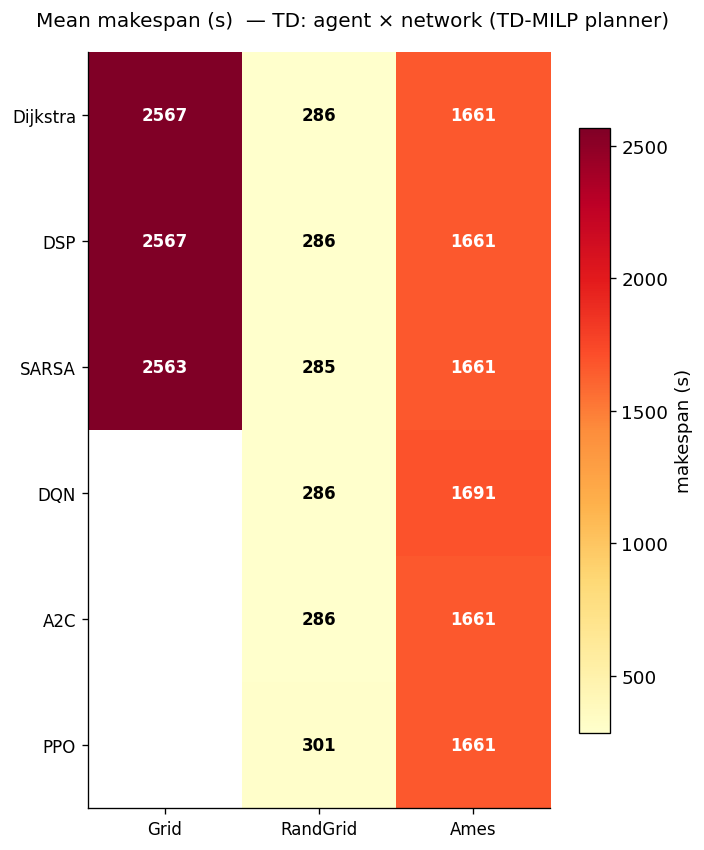

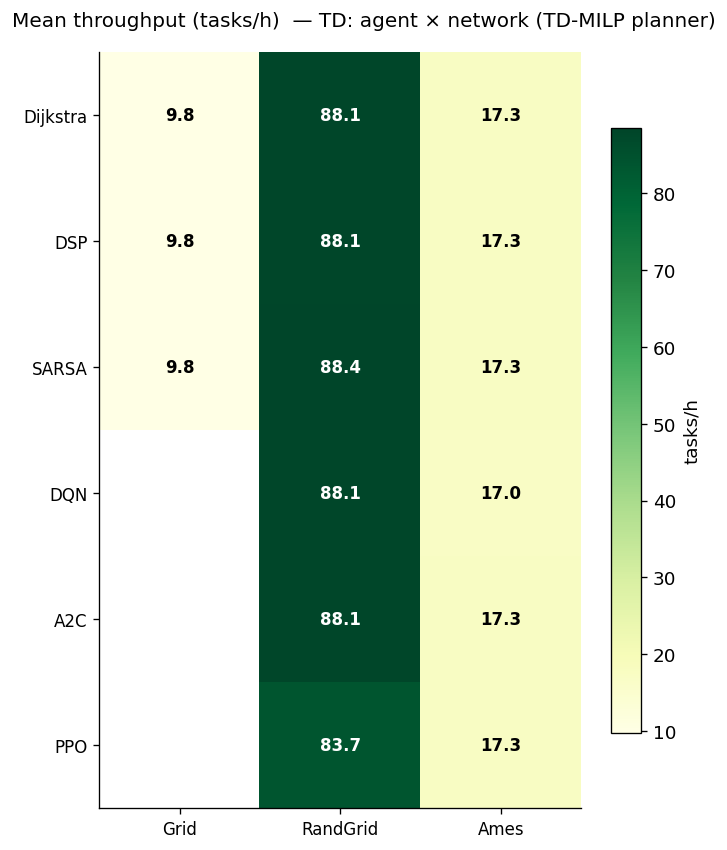

In [13]:
# ── TD: heatmaps — agent × network ────────────────────────────────────────────
if not td_df.empty and TD_AGENT_ORDER:
    td_nets = [n for n in NET_ORDER if n in td_df['network'].unique()]

    for metric, cmap, label, title in [
        ('makespan_s',             'YlOrRd', 'makespan (s)', 'Mean makespan (s)  — TD'),
        ('throughput_tasks_per_h', 'YlGn',   'tasks/h',      'Mean throughput (tasks/h)  — TD'),
    ]:
        fig, ax = plt.subplots(figsize=(max(6, 1.8 * len(td_nets)), max(3, 1.2 * len(TD_AGENT_ORDER))))
        fig.suptitle(f'{title}: agent × network (TD-MILP planner)', fontsize=12)

        pivot = (td_df.groupby(['agent', 'network'])[metric].mean()
                 .unstack('network')
                 .reindex(index=TD_AGENT_ORDER, columns=td_nets))
        vals = pivot.values.astype(float)

        valid = vals[~np.isnan(vals)]
        vmin, vmax = (valid.min(), valid.max()) if len(valid) else (0, 1)

        im = ax.imshow(vals, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_xticks(range(len(td_nets)))
        ax.set_xticklabels(td_nets, fontsize=10)
        ax.set_yticks(range(len(TD_AGENT_ORDER)))
        ax.set_yticklabels([TD_AGENT_LABELS.get(a, a) for a in TD_AGENT_ORDER], fontsize=10)

        for i in range(len(TD_AGENT_ORDER)):
            for j in range(len(td_nets)):
                v = vals[i, j]
                if not np.isnan(v):
                    brightness = (v - vmin) / (vmax - vmin + 1e-9)
                    fmt = f'{v:.0f}' if metric == 'makespan_s' else f'{v:.1f}'
                    ax.text(j, i, fmt, ha='center', va='center', fontsize=10,
                            color='white' if brightness > 0.6 else 'black', fontweight='bold')

        plt.colorbar(im, ax=ax, shrink=0.8, label=label)
        fig.tight_layout()
        plt.show()

---
## Planner comparison

Mean metrics per planner, broken out by network, shown separately for PSL and SVC traffic.

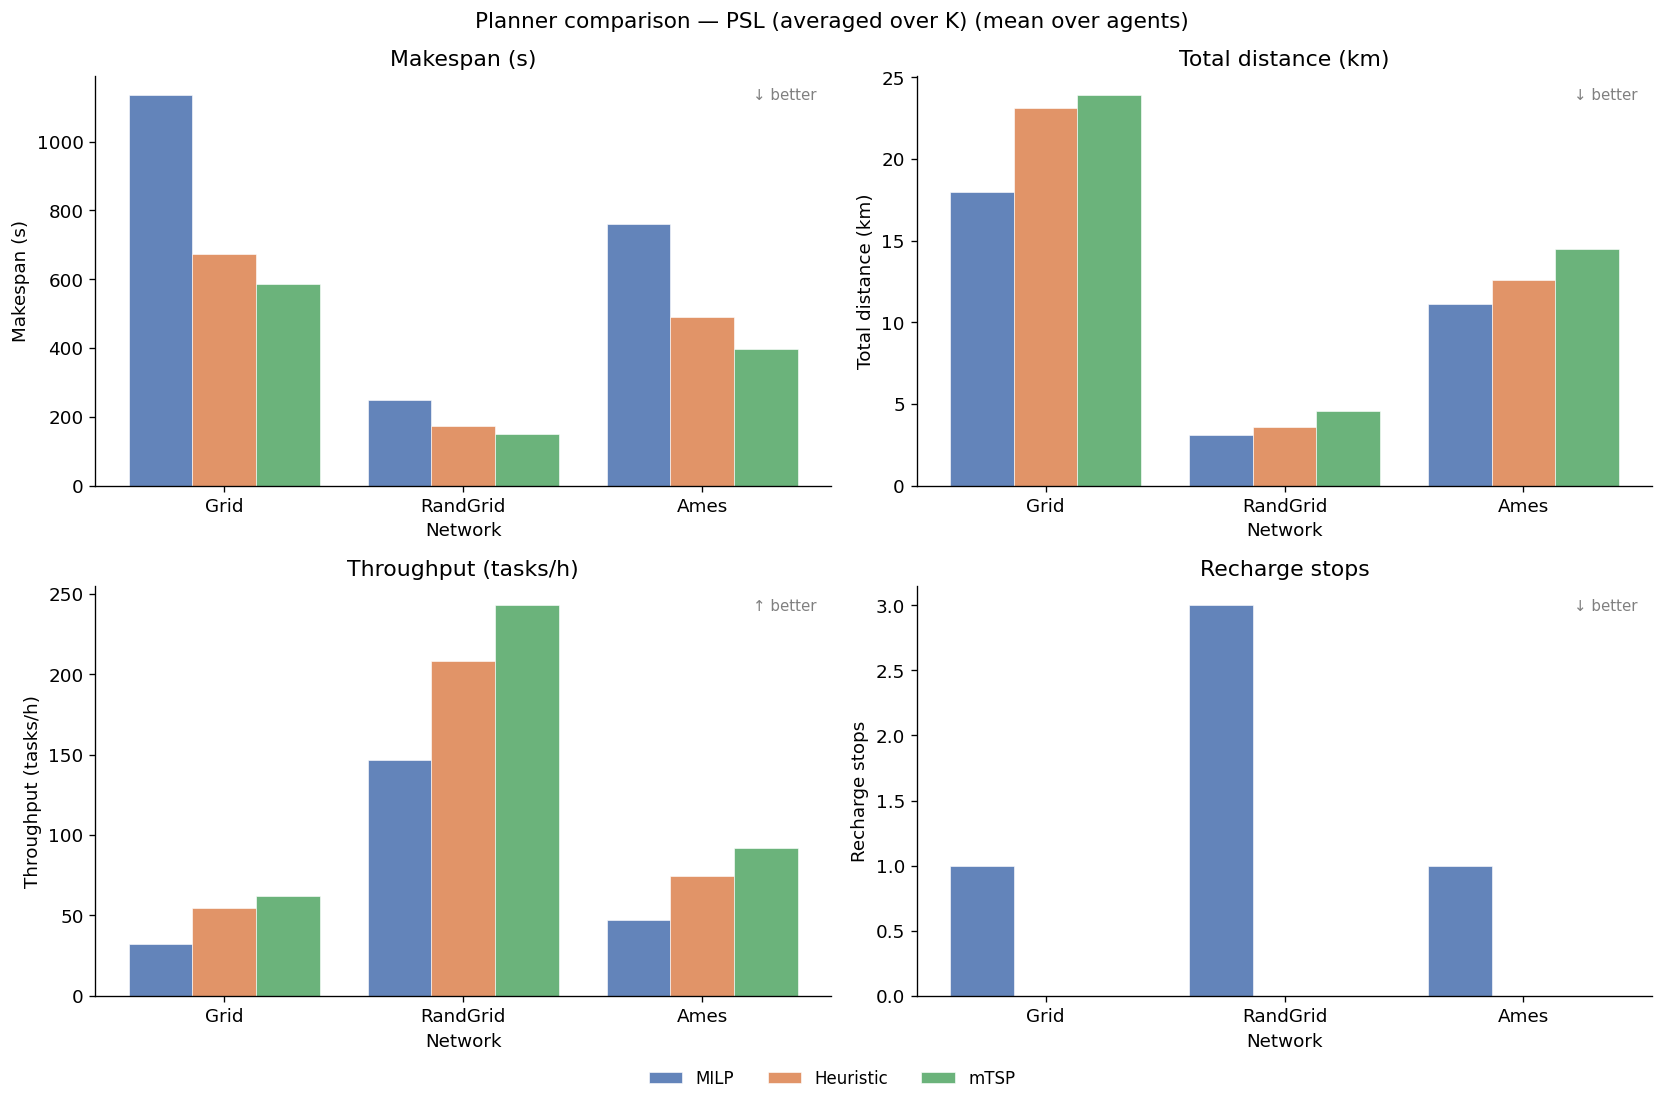

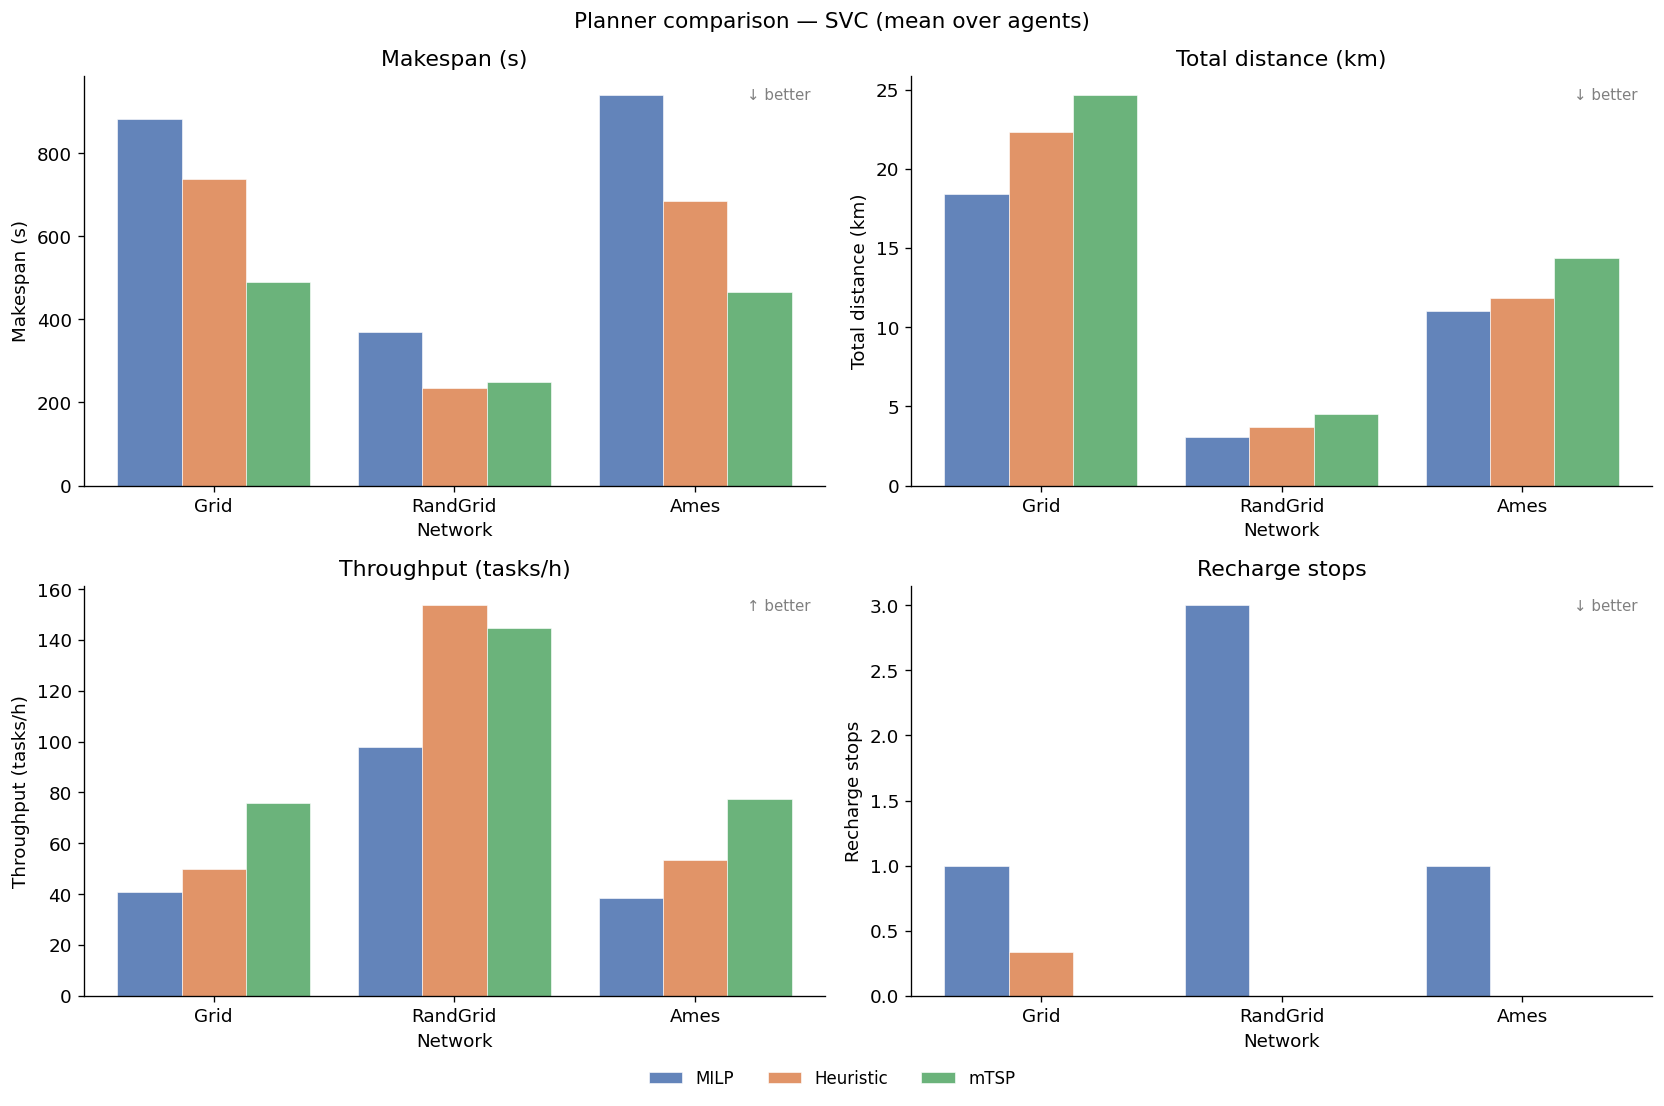

In [14]:
# ── Planner comparison: PSL vs SVC side-by-side ───────────────────────────────
x4      = np.arange(len(NET_ORDER))
width4  = 0.8 / len(PLANNER_ORDER)
off4    = np.linspace(-(len(PLANNER_ORDER)-1)/2*width4,
                       (len(PLANNER_ORDER)-1)/2*width4, len(PLANNER_ORDER))

for traffic_label, df_sub in [('PSL (averaged over K)', psl_df), ('SVC', svc_df)]:
    agg_pl = df_sub.groupby(['planner', 'network'])[METRICS].mean().reset_index()

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle(f'Planner comparison — {traffic_label} (mean over agents)', fontsize=13)

    for ax, (metric, ylabel, higher_better) in zip(axes.flat, [
        ('makespan_s',             'Makespan (s)',         False),
        ('total_distance_km',      'Total distance (km)',  False),
        ('throughput_tasks_per_h', 'Throughput (tasks/h)', True),
        ('total_recharges',        'Recharge stops',       False),
    ]):
        for off, planner in zip(off4, PLANNER_ORDER):
            vals = [
                agg_pl[(agg_pl['planner'] == planner) & (agg_pl['network'] == net)][metric].mean()
                for net in NET_ORDER
            ]
            ax.bar(x4 + off, vals, width4, color=PLANNER_COLORS[planner], alpha=0.87,
                   label=planner, edgecolor='white', linewidth=0.4)
        ax.set_xticks(x4)
        ax.set_xticklabels(NET_ORDER)
        ax.set_xlabel('Network')
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel)
        ax.text(0.98, 0.97, '↑ better' if higher_better else '↓ better',
                transform=ax.transAxes, ha='right', va='top', fontsize=9, color='gray')

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(PLANNER_ORDER),
               bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=10)
    fig.tight_layout()
    plt.show()

---
## Raw data tables

In [15]:
# PSL raw
display_cols = ['planner', 'agent', 'network', 'K',
                'makespan_s', 'total_distance_km', 'total_recharges',
                'customers_served', 'throughput_tasks_per_h', 'avg_inter_customer_gap_s']
print("── PSL ──")
display(
    psl_df[display_cols].sort_values(['planner', 'network', 'agent', 'K']).round(2).reset_index(drop=True)
)

# SVC raw
svc_display_cols = ['planner', 'agent', 'network',
                    'makespan_s', 'total_distance_km', 'total_recharges',
                    'customers_served', 'throughput_tasks_per_h', 'avg_inter_customer_gap_s']
print("── SVC ──")
display(
    svc_df[svc_display_cols].sort_values(['planner', 'network', 'agent']).round(2).reset_index(drop=True)
)

# TD raw
if not td_df.empty:
    td_display_cols = ['agent', 'network',
                       'makespan_s', 'total_distance_km', 'total_recharges',
                       'customers_served', 'throughput_tasks_per_h', 'avg_inter_customer_gap_s']
    print("── TD ──")
    display(
        td_df[td_display_cols].sort_values(['network', 'agent']).round(2).reset_index(drop=True)
    )

── PSL ──


,planner,agent,network,K,makespan_s,total_distance_km,total_recharges,customers_served,throughput_tasks_per_h,avg_inter_customer_gap_s
0,Heuristic,a2c,Ames,1,461.0,11.95,0.0,10.0,78.09,37.67
1,Heuristic,a2c,Ames,2,539.0,11.95,0.0,10.0,66.79,52.56
2,Heuristic,a2c,Ames,3,538.0,11.96,0.0,10.0,66.91,44.56
3,Heuristic,a2c,Ames,4,439.0,12.81,0.0,10.0,82.00,34.11
4,Heuristic,dijkstra,Ames,1,461.0,11.95,0.0,10.0,78.09,37.67
...,...,...,...,...,...,...,...,...,...,...
211,mTSP,ppo,RandGrid,4,135.0,4.37,0.0,10.0,266.67,10.67
212,mTSP,sarsa,RandGrid,1,150.0,4.74,0.0,10.0,240.00,9.67
213,mTSP,sarsa,RandGrid,2,157.0,4.84,0.0,10.0,229.30,9.11
214,mTSP,sarsa,RandGrid,3,194.0,5.35,0.0,10.0,185.57,8.78


── SVC ──


,planner,agent,network,makespan_s,total_distance_km,total_recharges,customers_served,throughput_tasks_per_h,avg_inter_customer_gap_s
0,Heuristic,a2c_svc,Ames,650.0,11.95,0.0,10.0,55.38,50.00
1,Heuristic,dijkstra,Ames,650.0,11.95,0.0,10.0,55.38,50.00
2,Heuristic,dqn_svc,Ames,610.0,12.23,0.0,10.0,59.02,52.22
3,Heuristic,dsp,Ames,637.0,11.95,0.0,10.0,56.51,56.56
4,Heuristic,ppo_svc,Ames,637.0,11.95,0.0,10.0,56.51,56.56
5,Heuristic,sarsa_svc,Ames,929.0,10.99,0.0,10.0,38.75,73.00
6,Heuristic,a2c_svc,Grid,935.0,21.69,1.0,10.0,38.50,89.22
7,Heuristic,dijkstra,Grid,780.0,21.69,0.0,10.0,46.15,73.00
8,Heuristic,dqn_svc,Grid,710.0,25.65,1.0,10.0,50.70,64.89
9,Heuristic,dsp,Grid,608.0,21.69,0.0,10.0,59.21,49.67


── TD ──


,agent,network,makespan_s,total_distance_km,total_recharges,customers_served,throughput_tasks_per_h,avg_inter_customer_gap_s
0,a2c,Ames,1661.0,13.92,1.0,8.0,17.34,118.43
1,dijkstra,Ames,1661.0,13.92,1.0,8.0,17.34,118.43
2,dqn,Ames,1691.0,13.99,1.0,8.0,17.03,118.43
3,dsp,Ames,1661.0,13.92,1.0,8.0,17.34,118.43
4,ppo,Ames,1661.0,13.92,1.0,8.0,17.34,118.43
5,sarsa,Ames,1661.0,13.92,1.0,8.0,17.34,118.43
6,dijkstra,Grid,2567.0,21.69,1.0,7.0,9.82,238.67
7,dsp,Grid,2567.0,21.69,1.0,7.0,9.82,238.67
8,sarsa,Grid,2563.0,21.70,1.0,7.0,9.83,239.83
9,a2c,RandGrid,286.0,3.83,0.0,7.0,88.11,18.33
